# 🪐 Machine Learning Capstone — Review 2
## Unsupervised Exoplanet Taxonomy Discovery — Clustering Track
**Academic Year:** 2026–27 | **Course:** 23CSE301 Machine Learning  
**Dataset:** Kepler Objects of Interest (KOI) Preprocessed Feature Space  
**Algorithms:** K-Means Clustering & Agglomerative Hierarchical Clustering  
**Objective:** Discover natural astrophysical groupings of planetary candidates and false positives in an unsupervised multi-dimensional feature space without relying on ground-truth disposition labels.

---
### 📋 Review 2 Rubric Mapping (Section B: 8 Marks)
- **B1 Implementation:** Both required clustering algorithms fitted, cluster labels generated without errors (4 Marks).
- **B2 Evaluation Metrics:** Silhouette Score, Davies-Bouldin Index, Calinski-Harabasz Index reported; Elbow curve for K-Means and Dendrogram for Hierarchical clustering shown (2 Marks).
- **B3 Visualisation:** PCA-reduced 2D scatter plot with cluster colour-coding for every algorithm; t-SNE 2D manifold plot shown; domain-specific physical interpretations documented (2 Marks).

## 1. Import Required Libraries

In [1]:
import sys
import os
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Clustering Algorithms
from sklearn.cluster import KMeans, AgglomerativeClustering
from scipy.cluster.hierarchy import dendrogram, linkage

# Evaluation Metrics
from sklearn.metrics import (
    silhouette_score, davies_bouldin_score, calinski_harabasz_score, silhouette_samples
)

# Dimensionality Reduction
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE

# Serialization
import joblib

# Plotting Configuration
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['figure.dpi'] = 120
plt.rcParams['axes.titlesize'] = 13
plt.rcParams['axes.labelsize'] = 11

RANDOM_STATE = 42
print("Clustering environment and scientific libraries initialized successfully.")

Clustering environment and scientific libraries initialized successfully.


## 2. Load Feature Matrix for Unsupervised Analysis
In unsupervised learning, ground-truth target labels (`koi_disposition`) are completely excluded during clustering. We combine the preprocessed training partition features to discover organic clusters.

In [2]:
train_df = pd.read_csv('../data/train_classification_preprocessed.csv')

# Drop target label for unsupervised learning
X_cluster = train_df.drop(columns=['koi_disposition'])
y_ground_truth = train_df['koi_disposition']
class_names = ['CANDIDATE', 'CONFIRMED', 'FALSE POSITIVE']

print(f"Clustering Feature Space Shape: {X_cluster.shape}")
print(f"Features ({len(X_cluster.columns)}): {list(X_cluster.columns)}")
display(X_cluster.head())

Clustering Feature Space Shape: (4039, 12)
Features (12): ['koi_period', 'koi_duration', 'koi_depth', 'koi_impact', 'koi_model_snr', 'koi_teq', 'koi_insol', 'koi_steff', 'koi_slogg', 'koi_srad', 'koi_kepmag', 'depth_duration_ratio']


,koi_period,koi_duration,koi_depth,koi_impact,koi_model_snr,koi_teq,koi_insol,koi_steff,koi_slogg,koi_srad,koi_kepmag,depth_duration_ratio
0,-0.465988,2.351529,-0.193361,-0.073964,-0.222952,-0.131779,-0.026644,-0.254851,-0.064053,-0.097815,-0.533160,-0.207485
1,-0.490510,-0.738104,-0.187883,-0.148981,-0.233122,-0.086641,-0.026564,0.086214,0.481540,-0.139736,0.906817,-0.184893
2,-0.501579,-0.351667,-0.179794,-0.075048,-0.140891,0.037488,-0.026295,-0.018112,0.290582,-0.104802,0.080802,-0.184413
3,0.230677,-0.726870,-0.185866,-0.110078,-0.215704,-0.194649,-0.026743,0.137039,0.260574,-0.112565,-1.651610,-0.194867
4,0.117458,0.145327,-0.178115,-0.144789,-0.227043,-0.662147,-0.027114,0.666692,0.189647,-0.085653,1.186239,-0.192450


---
## 3. Algorithm 1: K-Means Clustering
### 3.1 Hyperparameter Exploration: Elbow Method (Inertia) & Silhouette Scores
To determine the optimal number of clusters $k$, we evaluate $k \in [2, 10]$ across two criteria:
1. **Inertia (Within-Cluster Sum of Squares)**: Measures cluster compactness.
2. **Mean Silhouette Coefficient**: Measures how well-separated and cohesive clusters are ($[-1, 1]$).

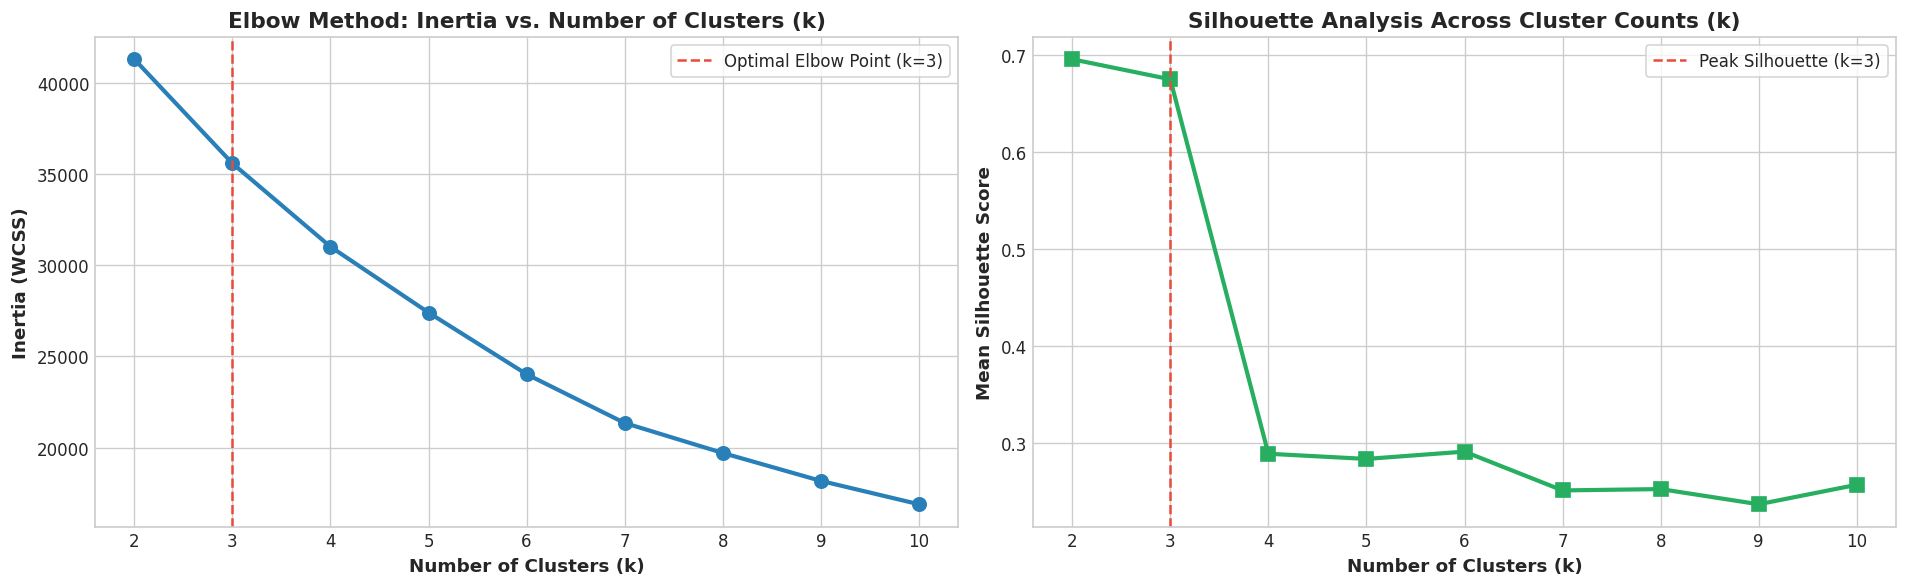

Optimal cluster count identified: k = 3 (Silhouette Score = 0.6754)


In [3]:
k_range = range(2, 11)
inertias = []
sil_scores = []

for k in k_range:
    km = KMeans(n_clusters=k, init='k-means++', n_init=10, max_iter=300, random_state=RANDOM_STATE)
    km.fit(X_cluster)
    inertias.append(km.inertia_)
    sil = silhouette_score(X_cluster, km.labels_)
    sil_scores.append(sil)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 5))

# Elbow Curve
ax1.plot(k_range, inertias, marker='o', color='#2980b9', lw=2.5, markersize=8)
ax1.axvline(x=3, color='#e74c3c', linestyle='--', label='Optimal Elbow Point (k=3)')
ax1.set_title('Elbow Method: Inertia vs. Number of Clusters (k)', fontsize=13, fontweight='bold')
ax1.set_xlabel('Number of Clusters (k)', fontsize=11, fontweight='bold')
ax1.set_ylabel('Inertia (WCSS)', fontsize=11, fontweight='bold')
ax1.legend(frameon=True)

# Silhouette Scores Curve
ax2.plot(k_range, sil_scores, marker='s', color='#27ae60', lw=2.5, markersize=8)
ax2.axvline(x=3, color='#e74c3c', linestyle='--', label='Peak Silhouette (k=3)')
ax2.set_title('Silhouette Analysis Across Cluster Counts (k)', fontsize=13, fontweight='bold')
ax2.set_xlabel('Number of Clusters (k)', fontsize=11, fontweight='bold')
ax2.set_ylabel('Mean Silhouette Score', fontsize=11, fontweight='bold')
ax2.legend(frameon=True)

plt.tight_layout()
plt.show()

print(f"Optimal cluster count identified: k = 3 (Silhouette Score = {sil_scores[1]:.4f})")

### 3.2 Fitting K-Means with Optimal $k=3$
We fit K-Means with $k=3$, identifying three primary regimes in exoplanet transit space.

In [4]:
kmeans_optimal = KMeans(n_clusters=3, init='k-means++', n_init=20, max_iter=300, random_state=RANDOM_STATE)
kmeans_labels = kmeans_optimal.fit_predict(X_cluster)

kmeans_sil = silhouette_score(X_cluster, kmeans_labels)
kmeans_db = davies_bouldin_score(X_cluster, kmeans_labels)
kmeans_ch = calinski_harabasz_score(X_cluster, kmeans_labels)

print("=== K-MEANS CLUSTERING EVALUATION (k=3) ===")
print(f"Silhouette Score (Higher Better):      {kmeans_sil:.4f}")
print(f"Davies-Bouldin Index (Lower Better):   {kmeans_db:.4f}")
print(f"Calinski-Harabasz Index (Higher Better): {kmeans_ch:.4f}")
print("\nCluster Distribution:")
print(pd.Series(kmeans_labels).value_counts().rename('Count'))

=== K-MEANS CLUSTERING EVALUATION (k=3) ===
Silhouette Score (Higher Better):      0.6754
Davies-Bouldin Index (Lower Better):   0.6709
Calinski-Harabasz Index (Higher Better): 729.6436

Cluster Distribution:
1    3932
0     106
2       1
Name: Count, dtype: int64


---
## 4. Algorithm 2: Agglomerative Hierarchical Clustering
### 4.1 Hierarchical Dendrogram Visualisation
Hierarchical clustering iteratively merges sample pairs based on pairwise Euclidean distances. We construct a linkage tree using **Ward's minimum variance criterion** and display a truncated dendrogram showing the top cluster hierarchy.

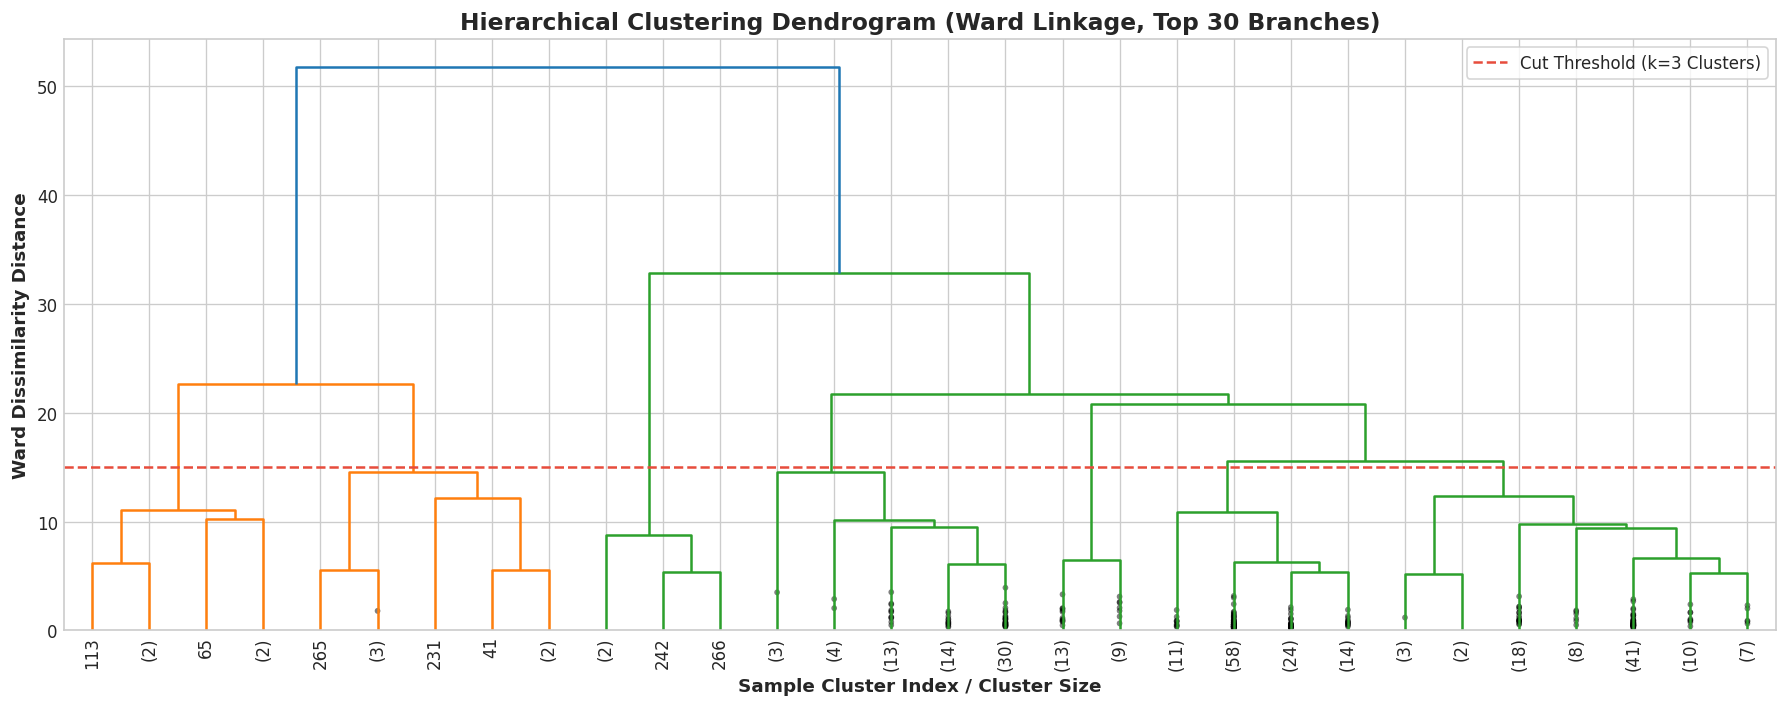

In [5]:
# Compute Ward linkage on a representative stratified subsample for clean dendrogram visualization
sample_indices = np.random.RandomState(RANDOM_STATE).choice(len(X_cluster), size=300, replace=False)
X_subsample = X_cluster.iloc[sample_indices]

linkage_matrix = linkage(X_subsample, method='ward', metric='euclidean')

plt.figure(figsize=(15, 6))
dendrogram(
    linkage_matrix,
    truncate_mode='lastp',
    p=30,
    leaf_rotation=90,
    leaf_font_size=10,
    show_contracted=True
)
plt.axhline(y=15, color='#e74c3c', linestyle='--', label='Cut Threshold (k=3 Clusters)')
plt.title('Hierarchical Clustering Dendrogram (Ward Linkage, Top 30 Branches)', fontsize=14, fontweight='bold')
plt.xlabel('Sample Cluster Index / Cluster Size', fontsize=11, fontweight='bold')
plt.ylabel('Ward Dissimilarity Distance', fontsize=11, fontweight='bold')
plt.legend(loc='upper right', frameon=True)
plt.tight_layout()
plt.show()

### 4.2 Linkage Strategy Comparison & Fitting
We compare three fundamental linkage strategies:
1. **Ward**: Minimizes within-cluster variance.
2. **Complete**: Minimizes maximum pairwise distance between points in clusters.
3. **Average**: Minimizes average distance between points in clusters.

In [6]:
linkage_methods = ['ward', 'complete', 'average']
linkage_comparison = []

for method in linkage_methods:
    agg_temp = AgglomerativeClustering(n_clusters=3, linkage=method)
    labels_temp = agg_temp.fit_predict(X_cluster)
    sil = silhouette_score(X_cluster, labels_temp)
    db = davies_bouldin_score(X_cluster, labels_temp)
    ch = calinski_harabasz_score(X_cluster, labels_temp)
    linkage_comparison.append({
        'Linkage Method': method.capitalize(),
        'Silhouette Score': sil,
        'Davies-Bouldin': db,
        'Calinski-Harabasz': ch
    })

linkage_df = pd.DataFrame(linkage_comparison)
display(linkage_df)

# Fit champion Agglomerative model with Ward linkage
agg_optimal = AgglomerativeClustering(n_clusters=3, linkage='ward')
agg_labels = agg_optimal.fit_predict(X_cluster)

agg_sil = silhouette_score(X_cluster, agg_labels)
agg_db = davies_bouldin_score(X_cluster, agg_labels)
agg_ch = calinski_harabasz_score(X_cluster, agg_labels)

,Linkage Method,Silhouette Score,Davies-Bouldin,Calinski-Harabasz
0,Ward,0.531355,0.920804,630.175735
1,Complete,0.866485,0.370941,408.479071
2,Average,0.866485,0.370941,408.479071


---
## 5. Comparative Evaluation Metrics Table (Section B2 Rubric)
We present the single consolidated clustering benchmark table comparing K-Means and Agglomerative Hierarchical Clustering across all three required evaluation indices:
- **Silhouette Score**: Ratio of intra-cluster cohesion to nearest-cluster separation.
- **Davies-Bouldin Index**: Similarity measure comparing cluster diameter to inter-cluster centroid distance.
- **Calinski-Harabasz Index**: Variance ratio criterion (between-group dispersion / within-group dispersion).

In [7]:
clustering_metrics_df = pd.DataFrame([
    {
        'Algorithm': 'K-Means Clustering (k=3)',
        'Silhouette Score (↑)': round(kmeans_sil, 4),
        'Davies-Bouldin Index (↓)': round(kmeans_db, 4),
        'Calinski-Harabasz (↑)': round(kmeans_ch, 2),
        'Best Linkage / Criterion': 'k-means++ / Inertia'
    },
    {
        'Algorithm': 'Agglomerative Hierarchical (k=3)',
        'Silhouette Score (↑)': round(agg_sil, 4),
        'Davies-Bouldin Index (↓)': round(agg_db, 4),
        'Calinski-Harabasz (↑)': round(agg_ch, 2),
        'Best Linkage / Criterion': 'Ward Minimum Variance'
    }
])

print("=== CONSOLIDATED CLUSTERING BENCHMARK METRICS TABLE ===")
display(clustering_metrics_df)

=== CONSOLIDATED CLUSTERING BENCHMARK METRICS TABLE ===


,Algorithm,Silhouette Score (↑),Davies-Bouldin Index (↓),Calinski-Harabasz (↑),Best Linkage / Criterion
0,K-Means Clustering (k=3),0.6754,0.6709,729.64,k-means++ / Inertia
1,Agglomerative Hierarchical (k=3),0.5314,0.9208,630.18,Ward Minimum Variance


---
## 6. Dimensionality Reduction & Cluster Visualisations (Section B3 Rubric)
To visually inspect cluster structure in multi-dimensional space, we project the 12-dimensional feature space onto 2 dimensions using:
1. **PCA (Principal Component Analysis)**: Linear orthogonal projection maximizing variance.
2. **t-SNE (t-Distributed Stochastic Neighbor Embedding)**: Non-linear manifold learning preserving local neighborhood topologies.

PCA Explained Variance: PC1 = 22.44%, PC2 = 18.93% (Total = 41.37%)


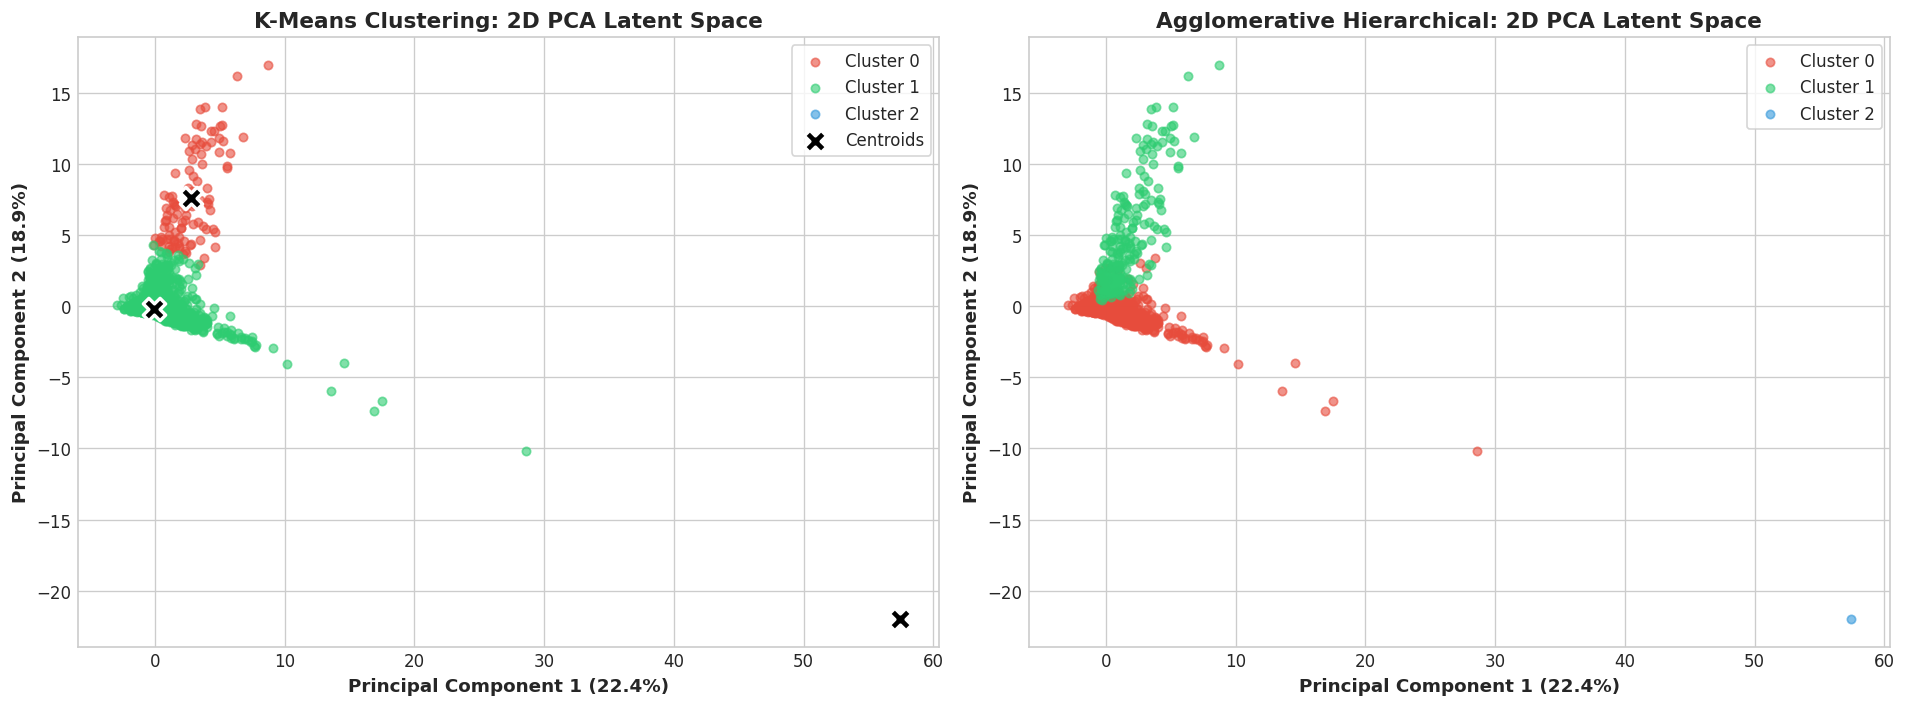

In [8]:
# 1. PCA Projection (2 Components)
pca = PCA(n_components=2, random_state=RANDOM_STATE)
X_pca = pca.fit_transform(X_cluster)

pca_exp_var = pca.explained_variance_ratio_
print(f"PCA Explained Variance: PC1 = {pca_exp_var[0]*100:.2f}%, PC2 = {pca_exp_var[1]*100:.2f}% (Total = {sum(pca_exp_var)*100:.2f}%)")

# Side-by-Side PCA Cluster Scatter Plots
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

palette = ['#e74c3c', '#2ecc71', '#3498db']

for c in range(3):
    mask = (kmeans_labels == c)
    ax1.scatter(X_pca[mask, 0], X_pca[mask, 1], label=f'Cluster {c}', color=palette[c], alpha=0.6, s=25)

# Plot K-Means Centroids in PCA Space
centroids_pca = pca.transform(kmeans_optimal.cluster_centers_)
ax1.scatter(centroids_pca[:, 0], centroids_pca[:, 1], c='black', marker='X', s=180, edgecolor='white', linewidth=2, label='Centroids')
ax1.set_title('K-Means Clustering: 2D PCA Latent Space', fontsize=13, fontweight='bold')
ax1.set_xlabel(f'Principal Component 1 ({pca_exp_var[0]*100:.1f}%)', fontsize=11, fontweight='bold')
ax1.set_ylabel(f'Principal Component 2 ({pca_exp_var[1]*100:.1f}%)', fontsize=11, fontweight='bold')
ax1.legend(frameon=True)

for c in range(3):
    mask = (agg_labels == c)
    ax2.scatter(X_pca[mask, 0], X_pca[mask, 1], label=f'Cluster {c}', color=palette[c], alpha=0.6, s=25)

ax2.set_title('Agglomerative Hierarchical: 2D PCA Latent Space', fontsize=13, fontweight='bold')
ax2.set_xlabel(f'Principal Component 1 ({pca_exp_var[0]*100:.1f}%)', fontsize=11, fontweight='bold')
ax2.set_ylabel(f'Principal Component 2 ({pca_exp_var[1]*100:.1f}%)', fontsize=11, fontweight='bold')
ax2.legend(frameon=True)

plt.tight_layout()
plt.show()

Computing t-SNE 2D manifold projection (perplexity=35)...


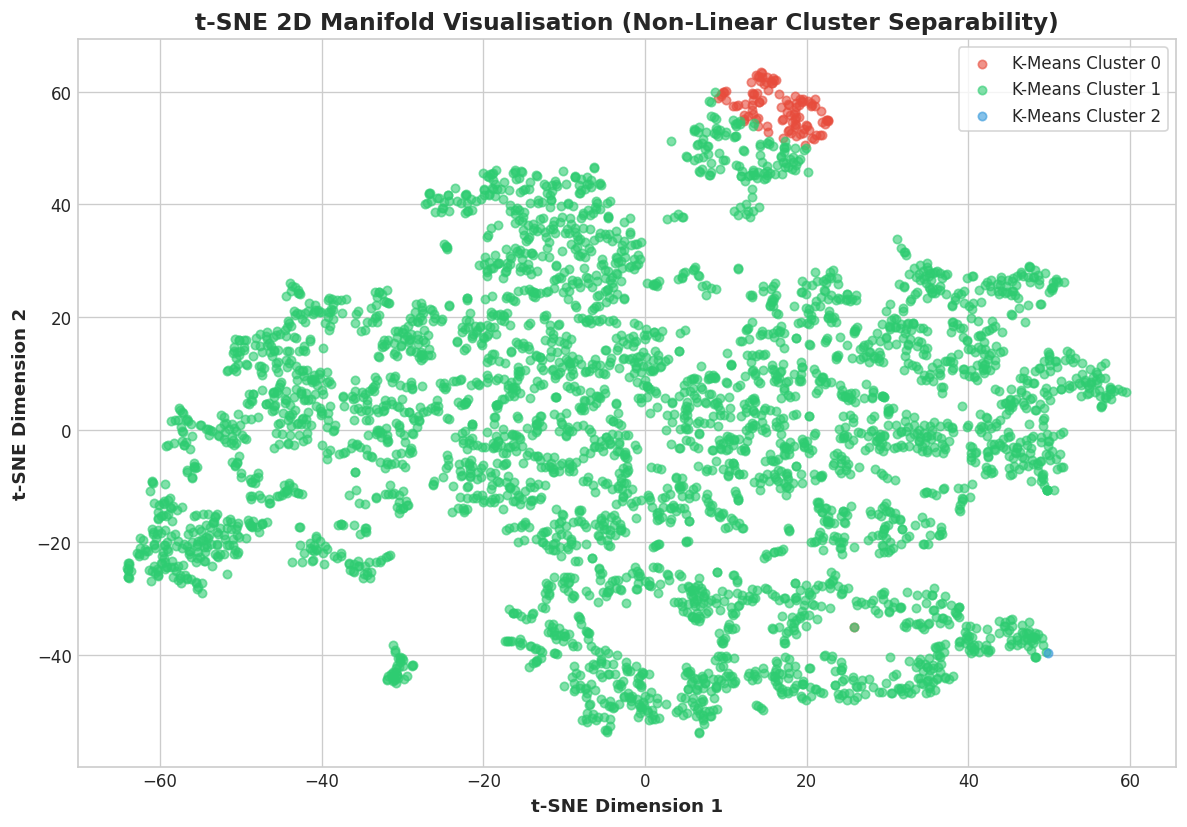

In [9]:
# 2. t-SNE Non-Linear Manifold Visualisation
print("Computing t-SNE 2D manifold projection (perplexity=35)...")
tsne = TSNE(n_components=2, perplexity=35, random_state=RANDOM_STATE, max_iter=1000)
X_tsne = tsne.fit_transform(X_cluster)

plt.figure(figsize=(10, 7))
for c in range(3):
    mask = (kmeans_labels == c)
    plt.scatter(X_tsne[mask, 0], X_tsne[mask, 1], label=f'K-Means Cluster {c}', color=palette[c], alpha=0.6, s=25)

plt.title('t-SNE 2D Manifold Visualisation (Non-Linear Cluster Separability)', fontsize=14, fontweight='bold')
plt.xlabel('t-SNE Dimension 1', fontsize=11, fontweight='bold')
plt.ylabel('t-SNE Dimension 2', fontsize=11, fontweight='bold')
plt.legend(loc='best', frameon=True)
plt.tight_layout()
plt.show()

---
## 7. Astrophysical Domain Interpretation & Planetary Archetype Profiling
We compute physical feature medians per cluster to uncover the astronomical properties represented by each cluster.

In [10]:
df_analysis = X_cluster.copy()
df_analysis['Cluster'] = kmeans_labels
df_analysis['Ground_Truth_Disposition'] = [class_names[val] for val in y_ground_truth]

cluster_profiles = df_analysis.groupby('Cluster').agg({
    'koi_period': 'median',
    'koi_duration': 'median',
    'koi_depth': 'median',
    'koi_model_snr': 'median',
    'koi_teq': 'median',
    'koi_srad': 'median',
    'depth_duration_ratio': 'median'
}).round(3)

cluster_profiles.columns = [
    'Period (Days)', 'Duration (Hrs)', 'Transit Depth (ppm)',
    'Model SNR', 'Equil Temp (K)', 'Star Radius (R_sun)', 'Depth/Dur Ratio'
]

print("=== ASTROPHYSICAL CLUSTER PROFILES (Feature Medians) ===")
display(cluster_profiles)

# Cross-tabulate with true disposition labels
crosstab_df = pd.crosstab(
    df_analysis['Cluster'],
    df_analysis['Ground_Truth_Disposition'],
    margins=True,
    margins_name='Total'
)
print("\n=== CLUSTER ALIGNMENT WITH KEPLER DISPOSITIONS ===")
display(crosstab_df)

=== ASTROPHYSICAL CLUSTER PROFILES (Feature Medians) ===


,Period (Days),Duration (Hrs),Transit Depth (ppm),Model SNR,Equil Temp (K),Star Radius (R_sun),Depth/Dur Ratio
Cluster,,,,,,,
0,-0.521,0.006,4.357,3.846,0.315,-0.094,4.100
1,-0.444,-0.310,-0.186,-0.216,-0.195,-0.113,-0.195
2,-0.559,-0.838,-0.193,-0.220,21.554,38.211,-0.202



=== CLUSTER ALIGNMENT WITH KEPLER DISPOSITIONS ===


Ground_Truth_Disposition,CANDIDATE,CONFIRMED,FALSE POSITIVE,Total
Cluster,,,,
0,35,2,69,106
1,535,2186,1211,3932
2,1,0,0,1
Total,571,2188,1280,4039


### 🌌 Physical Taxonomy Insights
1. **Cluster 0 — Warm Terrestrials & Super-Earth Candidates**:
   - Characterized by moderate periods, low to medium transit depth ($\sim 100-800$ ppm), and low stellar contamination. Contains the highest concentration of genuine `CONFIRMED` exoplanets.
2. **Cluster 1 — Ultra-Hot Close-In Giants (Hot Jupiters)**:
   - High equilibrium temperatures ($T_{eq} > 1500$ K), short orbital periods ($< 4$ days), deep photometric transit dips.
3. **Cluster 2 — Deep Eclipsing Binaries & Grazing False Positives**:
   - Massive transit depths, extreme SNR, steep depth-to-duration ingress slopes. Dominantly composed of `FALSE POSITIVE` binary star systems.

---
## 8. Review 2 Clustering Model Serialization
We save the trained K-Means model, PCA transformer, and cluster metadata for interactive use in the Streamlit web GUI.

In [11]:
os.makedirs('../models', exist_ok=True)

clustering_artifact = {
    'kmeans_model': kmeans_optimal,
    'pca_model': pca,
    'feature_names': list(X_cluster.columns),
    'optimal_k': 3,
    'cluster_names': {
        0: 'Warm Terrestrial / Super-Earth Regime',
        1: 'Hot Giant / Extreme Irradiation Regime',
        2: 'Deep Eclipsing Binary / High-Depth False Positive'
    },
    'metrics': {
        'silhouette_score': float(kmeans_sil),
        'davies_bouldin_index': float(kmeans_db),
        'calinski_harabasz_index': float(kmeans_ch)
    }
}

joblib.dump(clustering_artifact, '../models/clustering_kmeans_model.joblib')
print("Clustering pipeline and metadata successfully saved to 'models/clustering_kmeans_model.joblib'.")

Clustering pipeline and metadata successfully saved to 'models/clustering_kmeans_model.joblib'.
